In [27]:
# use gpsa2 env
%load_ext autoreload
%autoreload 2
from plot_utils import callback_twod2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
import numpy as np
import anndata
import scanpy as sc

In [29]:
import scanpy as sc 

#run using env_stalign from here
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad

refExpression = pd.read_csv('refSubAD_expression.csv', index_col=0)
queryExpression = pd.read_csv('querySubAD_expression.csv', index_col=0)
refObs = pd.read_csv('refSubAD_obs.csv', index_col=0)
queryObs = pd.read_csv('querySubAD_obs.csv', index_col=0)

refAD = ad.AnnData(X=refExpression.values, obs=refObs)
queryAD = ad.AnnData(X=queryExpression.values, obs=queryObs)

refAD.var_names = refExpression.columns
queryAD.var_names = queryExpression.columns


/tmp/ipykernel_173782/2295923737.py:16: FutureWarning: X.dtype being converted to np.float32 from int64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  refAD = ad.AnnData(X=refExpression.values, obs=refObs)
/home/adyprat/anaconda3/envs/gpsa2/lib/python3.9/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/tmp/ipykernel_173782/2295923737.py:17: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  queryAD = ad.AnnData(X=queryExpression.values, obs=queryObs)


In [30]:

refAD.obsm['spatial'] = refAD.obs[['New_X','New_Y']].values
queryAD.obsm['spatial'] = queryAD.obs[['New_X','New_Y']].values

adata1 = refAD.copy()
adata2 = queryAD.copy()
adata1.obs['batch'] = 'rep1'
adata2.obs['batch'] = 'rep2'


In [55]:
# Normalize spatial coordinates to 0-10 range for both adata1 and adata2
# Normalize x and y coordinates separately
def normalize_spatial_separately(coords, min_val=0, max_val=100):
    normalized = coords.copy()
    for i in range(2):  # For x (0th column) and y (1st column)
        min_coord = coords[:, i].min()
        max_coord = coords[:, i].max()
        normalized[:, i] = min_val + (coords[:, i] - min_coord) * (max_val - min_val) / (max_coord - min_coord)
    return normalized

adata1.obsm['spatial'] = normalize_spatial_separately(adata1.obsm['spatial'])
adata2.obsm['spatial'] = normalize_spatial_separately(adata2.obsm['spatial'])
# adata1.obsm['spatial'] = 50+0.5*adata1.obsm['spatial']
# adata2.obsm['spatial'] = 50+0.5*adata2.obsm['spatial']

# Verify normalization
print("adata1 spatial range x:", adata1.obsm['spatial'][:, 0].min(), "-", adata1.obsm['spatial'][:, 0].max())
print("adata1 spatial range y:", adata1.obsm['spatial'][:, 1].min(), "-", adata1.obsm['spatial'][:, 1].max())
print("adata2 spatial range x:", adata2.obsm['spatial'][:, 0].min(), "-", adata2.obsm['spatial'][:, 0].max())
print("adata2 spatial range y:", adata2.obsm['spatial'][:, 1].min(), "-", adata2.obsm['spatial'][:, 1].max())




adata1 spatial range x: 0.0 - 100.0
adata1 spatial range y: 0.0 - 100.0
adata2 spatial range x: 0.0 - 100.0
adata2 spatial range y: 0.0 - 100.0


In [56]:
outAD = sc.concat([adata1, adata2])
outAD.obs['batch'].value_counts()
outAD


AnnData object with n_obs × n_vars = 8279 × 16
    obs: 'transformed_x', 'transformed_y', 'in_ROI', 'New_X', 'New_Y', 'CellType', 'image_id', 'spatial_domain', 'batch'
    obsm: 'spatial'

In [57]:
outAD.var_names == adata2.var_names , outAD.var_names == adata1.var_names

(array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True]),
 array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True]))

In [58]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from gpsa import VariationalGPSA, GPSA
from gpsa import matern12_kernel, rbf_kernel
from gpsa.plotting import callback_twod

device = "cuda:0" if torch.cuda.is_available() else "cpu"

In [59]:

X = outAD.obsm["spatial"]
Y = outAD.X
view_idx = [np.where(outAD.obs.batch.values == ii)[0] for ii in ['rep1', 'rep2']]
n_samples_list = [len(x) for x in view_idx]

x = torch.from_numpy(X).float().clone().to(device)
y = torch.from_numpy(Y).float().clone().to(device)

data_dict = {
    "expression": {
        "spatial_coords": x,
        "outputs": y,
        "n_samples_list": n_samples_list,
    }
}
n_samples_list, view_idx

([3608, 4671],
 [array([   0,    1,    2, ..., 3605, 3606, 3607]),
  array([3608, 3609, 3610, ..., 8276, 8277, 8278])])

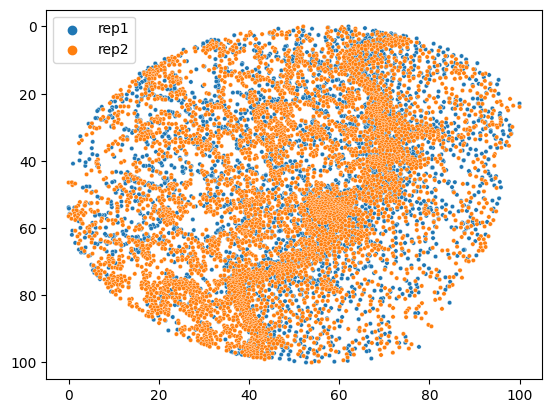

In [60]:
sns.scatterplot(x=outAD.obsm["spatial"][:,0],y=outAD.obsm["spatial"][:,1],hue=outAD.obs['batch'].values,s=10)
plt.gca().invert_yaxis()




In [61]:
print(torch.cuda.is_available())
print(torch.cuda.current_device())
print(torch.cuda.get_device_name(torch.cuda.current_device()))

True
0
NVIDIA TITAN RTX


In [62]:
# import torch
# X = data.obsm["spatial"]
# Y = data.X
# view_idx = [np.where(data.obs.batch.values == ii)[0] for ii in range(2)]
# n_samples_list = [len(x) for x in view_idx]

# x = torch.from_numpy(X).float().clone().to(device)
# y = torch.from_numpy(Y).float().clone().to(device)

# data_dict = {
#     "expression": {
#         "spatial_coords": x,
#         "outputs": y,
#         "n_samples_list": n_samples_list,
#     }
# }


In [63]:


N_SPATIAL_DIMS = 2
N_VIEWS = 2
M_G = 50
M_X_PER_VIEW = 50
N_OUTPUTS = 5
FIXED_VIEW_IDX = 0
N_LATENT_GPS = {"expression": None}

N_EPOCHS = 1000
PRINT_EVERY = 100

model = VariationalGPSA(
    data_dict,
    n_spatial_dims=N_SPATIAL_DIMS,
    m_X_per_view=M_X_PER_VIEW,
    m_G=M_G,
    data_init=True,
    minmax_init=False,
    grid_init=False,
    n_latent_gps=N_LATENT_GPS,
    mean_function="identity_fixed",
    kernel_func_warp=rbf_kernel,
    kernel_func_data=rbf_kernel,
    fixed_view_idx=FIXED_VIEW_IDX,
).to(device)

view_idx, Ns, _, _ = model.create_view_idx_dict(data_dict)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [64]:
from plot_utils import callback_twod2

Iter: 100        LL -2.524e+07


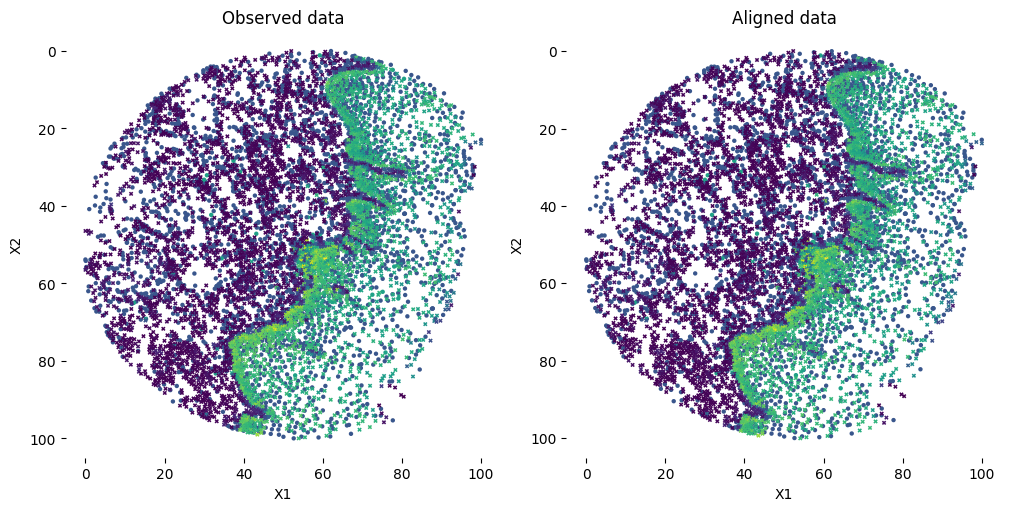

Iter: 200        LL -2.118e+07


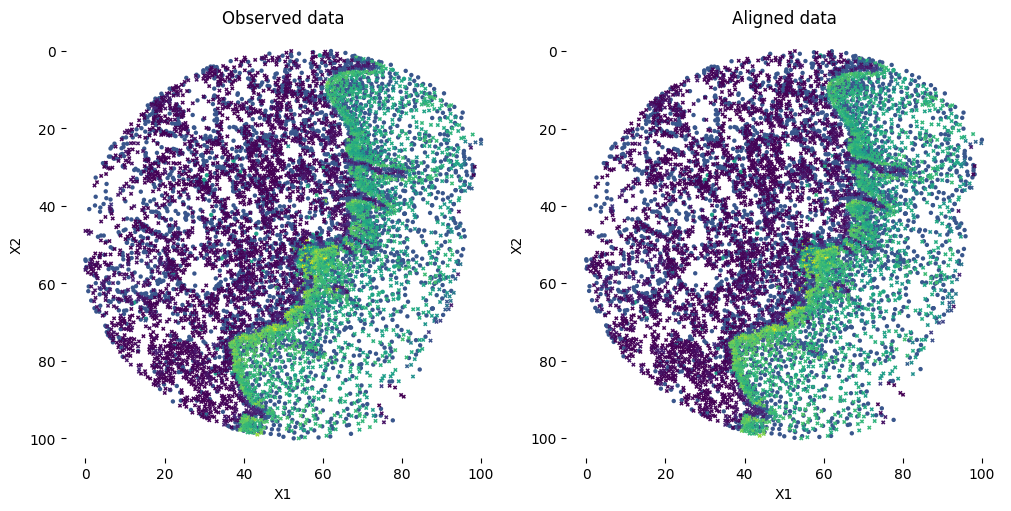

Iter: 300        LL -1.802e+07


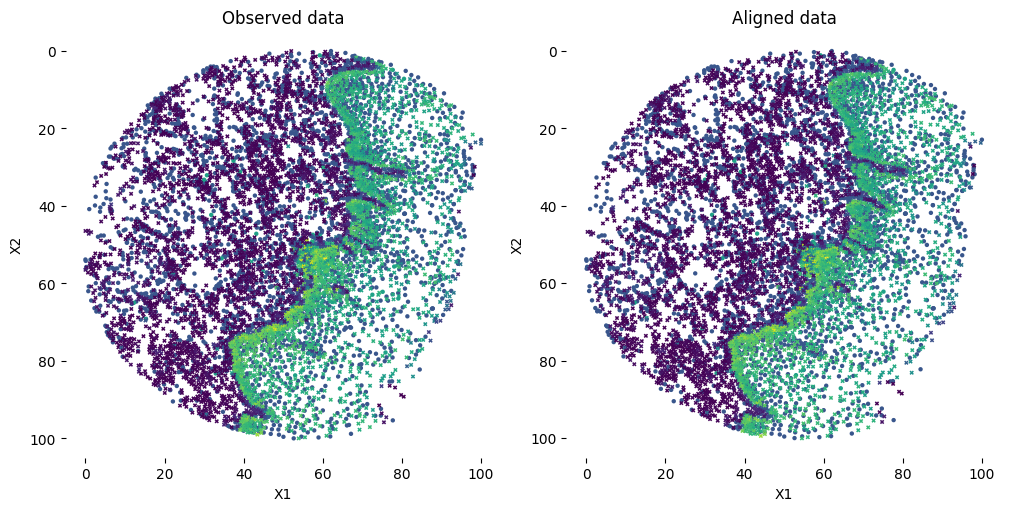

Iter: 400        LL -1.553e+07


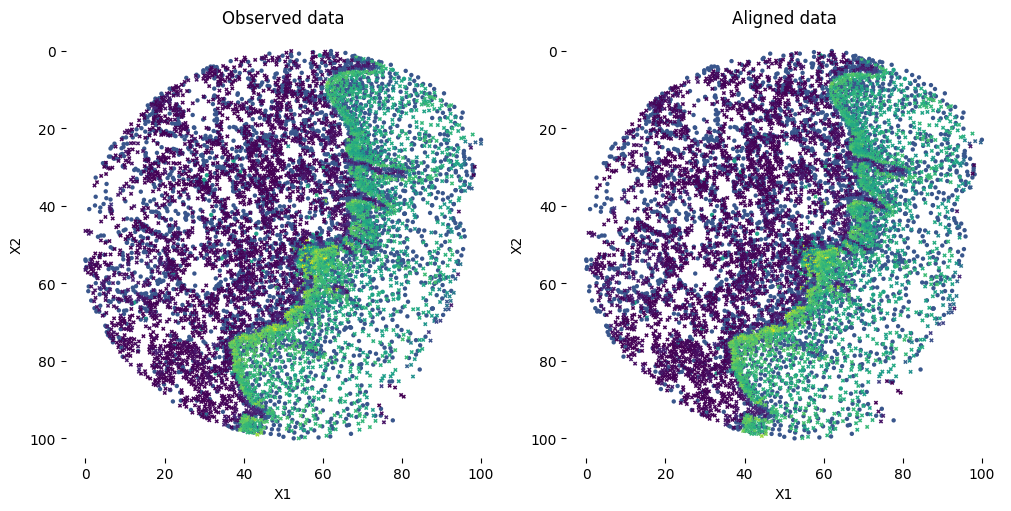

Iter: 500        LL -1.352e+07


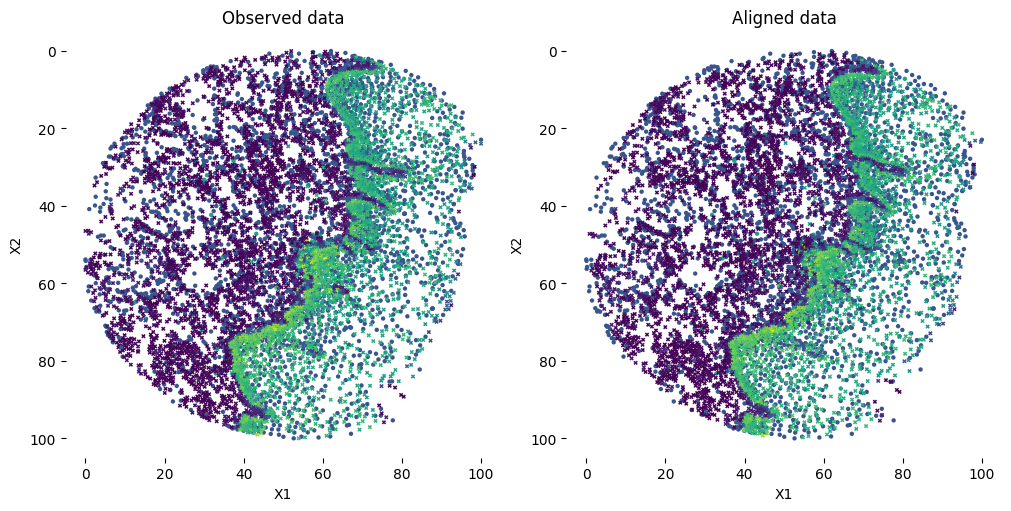

Iter: 600        LL -1.187e+07


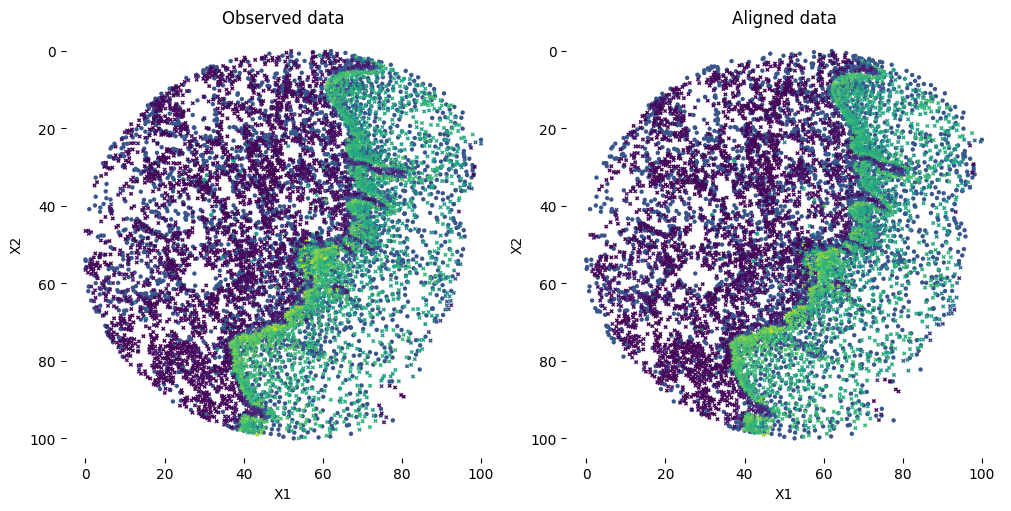

Iter: 700        LL -1.050e+07


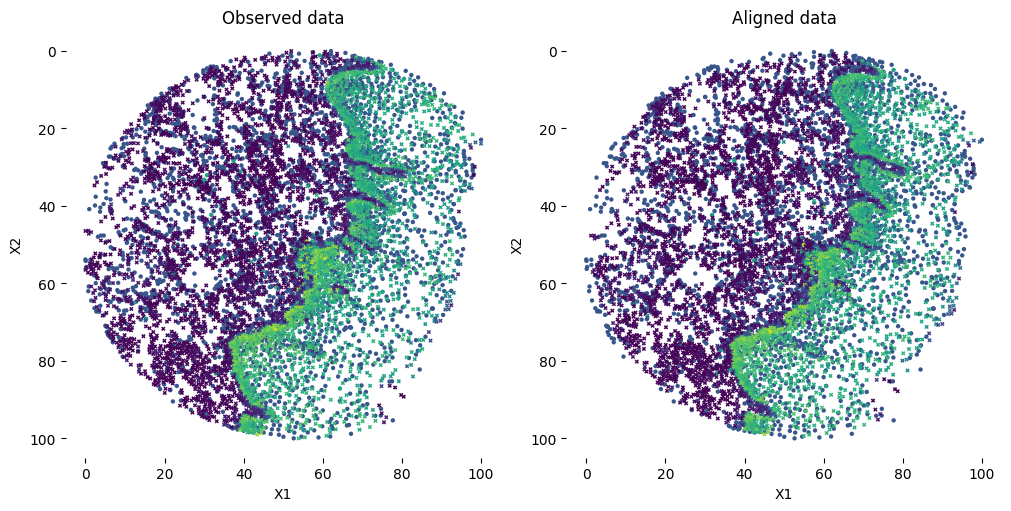

Iter: 800        LL -9.357e+06


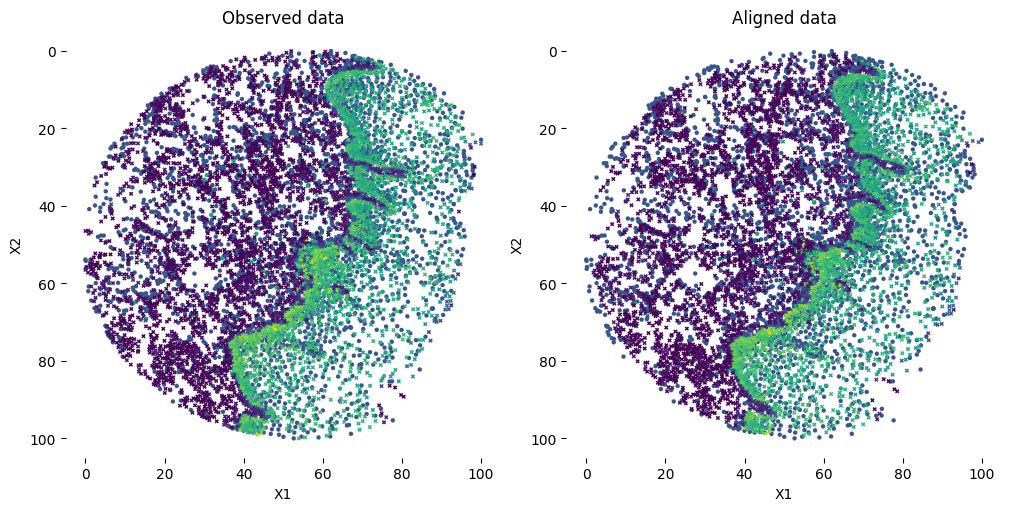

Iter: 900        LL -8.391e+06


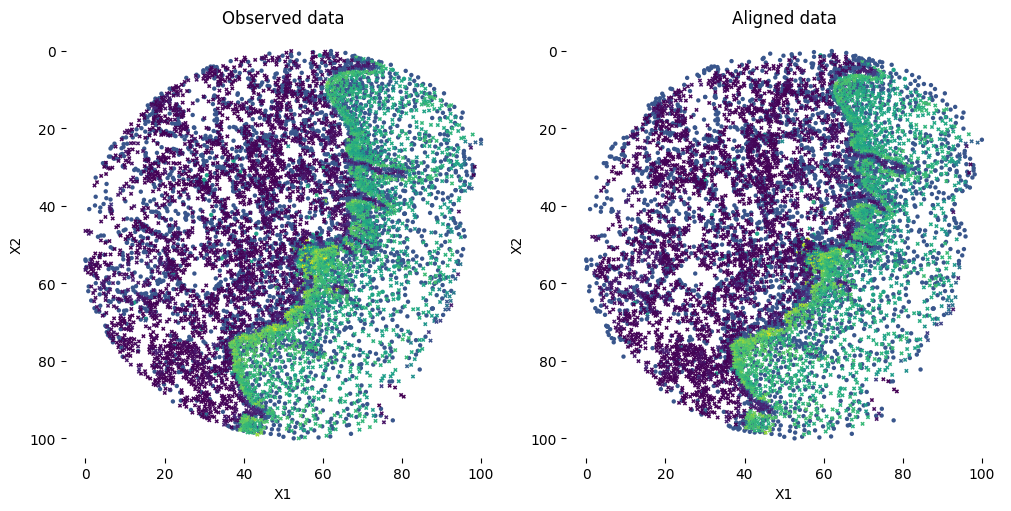

Done!


In [65]:
def train(model, loss_fn, optimizer):
    model.train()

    # Forward pass
    G_means, G_samples, F_latent_samples, F_samples = model.forward(
        {"expression": x}, view_idx=view_idx, Ns=Ns, S=5
    )

    # Compute loss
    loss = loss_fn(data_dict, F_samples)

    # Compute gradients and take optimizer step
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return loss.item()


# Set up figure.
fig = plt.figure(figsize=(10, 5), facecolor="white", constrained_layout=True)
data_expression_ax = fig.add_subplot(121, frameon=False)
latent_expression_ax = fig.add_subplot(122, frameon=False)
#plt.show(block=False)

for t in range(N_EPOCHS):
    loss = train(model, model.loss_fn, optimizer)

    if t>0 and t % PRINT_EVERY == 0:
        print("Iter: {0:<10} LL {1:1.3e}".format(t, -loss))
        G_means, _, _, _ = model.forward({"expression": x}, view_idx=view_idx, Ns=Ns)

        callback_twod2(
            model,
            X,
            Y,
            data_expression_ax=data_expression_ax,
            latent_expression_ax=latent_expression_ax,
            X_aligned=G_means,
            s=10,
        )
        #plt.gca().invert_yaxis()
        plt.draw()
        plt.pause(1 / 60.0)

print("Done!")

plt.close()

In [66]:
adata1.shape, adata2.shape

((3608, 16), (4671, 16))

In [67]:
outCoords = G_means['expression'].detach().cpu().numpy()
outCoords.shape



(8279, 2)

In [68]:

n_samples_per_view = adata1.shape[0]

view1_aligned_coords = outCoords[:n_samples_per_view]
view2_aligned_coords = outCoords[n_samples_per_view:]


In [69]:
adata2.obs['GPSA_X'] = view2_aligned_coords[:,0]
adata2.obs['GPSA_Y'] = view2_aligned_coords[:,1]

adata1.obs['GPSA_X'] = view1_aligned_coords[:,0]
adata1.obs['GPSA_Y'] = view1_aligned_coords[:,1]

<AxesSubplot:xlabel='GPSA_X', ylabel='GPSA_Y'>

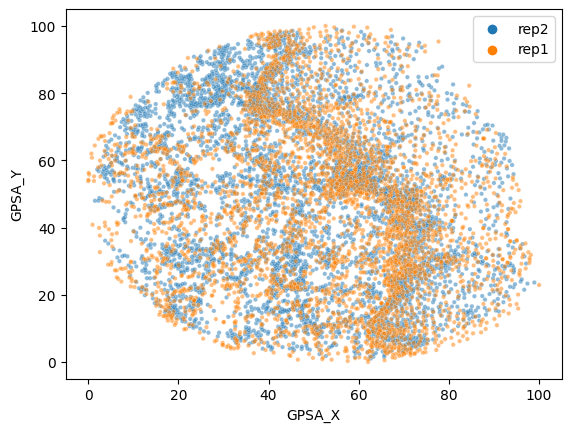

In [74]:
sns.scatterplot(x=adata2.obs['GPSA_X'],y=adata2.obs['GPSA_Y'],hue=adata2.obs['batch'].values,s=10, alpha=0.5)
sns.scatterplot(x=adata1.obs['GPSA_X'],y=adata1.obs['GPSA_Y'],hue=adata1.obs['batch'].values,palette='Set1_r',s=10, alpha=0.5)

In [71]:
adata1.obsm['X_GPSA_spatial'] = adata1.obs[['GPSA_X','GPSA_Y']].values
adata2.obsm['X_GPSA_spatial'] = adata2.obs[['GPSA_X','GPSA_Y']].values


In [75]:
adata2.write_h5ad('query_GPSA_Prot_tongue.h5ad')
adata1.write_h5ad('ref_GPSA_RNA_tongue.h5ad')
